# JS06 (Regresi) - Tugas: Multiple Linear Regression (Medical Cost)
**Mata Kuliah:** Pembelajaran Mesin  
**Dataset:** `insurance.csv` (Medical Cost Personal Datasets)  
**Nama:** Aryaputra | **NIM:** 244107020127  

---
### Instruksi
1. Identifikasi variabel bebas dan variabel target (`charges`).
2. Bagi dataset menjadi data latih dan uji (80:20).
3. Lakukan feature scaling dan encoding fitur kategorikal.
4. Bangun model Multiple Linear Regression dan evaluasi metrik $R^2$, MSE, RMSE, serta MAE.


   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520
R-squared (R2) : 0.7836
MSE            : 33,596,915.85
RMSE           : 5,796.28
MAE            : 4,181.19
<string>:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

              Fitur     Koefisien
4        smoker_yes  23651.128856
0               age   3614.975415
1               bmi   2036.228123
2          children    516.890247
3          sex_male    -18.591692
5  region_northwest   -370.677326
6  region_southeast   -657.864297
7  region_southwest   -809.799354


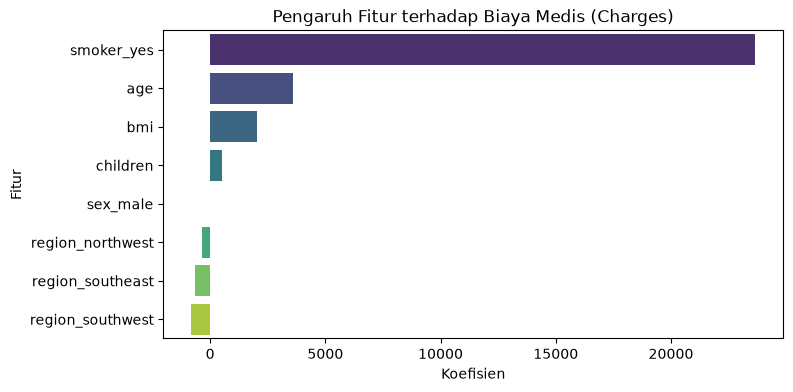

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# 1. Load Dataset
df = pd.read_csv('insurance.csv')
display(df.head())

# 2. Preprocessing & Splitting
X = df.drop(columns=['charges'])
y = df['charges']

num_cols = ['age', 'bmi', 'children']
cat_cols = ['sex', 'smoker', 'region']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first'), cat_cols)
    ]
)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Pipeline Multiple Linear Regression
model = Pipeline([
    ('prep', preprocessor),
    ('reg', LinearRegression())
])
model.fit(X_train, y_train)

# 4. Prediksi & Evaluasi
y_pred = model.predict(X_test)
print(f"R-squared (R2) : {r2_score(y_test, y_pred):.4f}")
print(f"MSE            : {mean_squared_error(y_test, y_pred):,.2f}")
print(f"RMSE           : {np.sqrt(mean_squared_error(y_test, y_pred)):,.2f}")
print(f"MAE            : {mean_absolute_error(y_test, y_pred):,.2f}")

# 5. Analisis Pengaruh Fitur
ohe_cols = list(model.named_steps['prep'].named_transformers_['cat'].get_feature_names_out(cat_cols))
all_cols = num_cols + ohe_cols
coefs = model.named_steps['reg'].coef_

df_coef = pd.DataFrame({'Fitur': all_cols, 'Koefisien': coefs}).sort_values(by='Koefisien', ascending=False)
plt.figure(figsize=(8, 4))
sns.barplot(data=df_coef, x='Koefisien', y='Fitur', palette='viridis')
plt.title("Pengaruh Fitur terhadap Biaya Medis (Charges)")
plt.show()
display(df_coef)


### Kesimpulan Tugas:
1. Model Multiple Linear Regression mencapai nilai **$R^2 = 0.7836$** pada data uji.
2. Fitur paling signifikan yang melipatgandakan biaya medis adalah status **`smoker_yes`**, diikuti usia (**`age`**) dan indeks massa tubuh (**`bmi`**).
